<a href="https://colab.research.google.com/github/teja01721/-human-like-conversational-chatbot-agent/blob/main/APS_Project_Updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
from xgboost import XGBRegressor
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.2f}'.format)

# ---- consistent visual theme ----
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False,
})
ACCENT  = '#4338ca'
HOT     = '#f97316'
GENDER_COLORS = {'male': '#0f766e', 'female': '#f97316'}
print('✅ Libraries loaded')

✅ Libraries loaded
✅ Libraries loaded


In [2]:
# Works on Google Colab (/content), locally, or from a data/ folder
def find_file(name):
    for path in [name, f'/content/{name}', f'data/{name}']:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"'{name}' not found. On Colab, upload it using the 📁 Files panel on the left.")

exercise_data = pd.read_csv(find_file('exercise.csv'))
calories      = pd.read_csv(find_file('calories.csv'))

# Join on User_ID (safer than concatenating side-by-side, which silently breaks if row order differs)
calories_data = exercise_data.merge(calories, on='User_ID', how='inner')

print(f'exercise.csv : {exercise_data.shape}')
print(f'calories.csv : {calories.shape}')
print(f'merged       : {calories_data.shape[0]:,} rows × {calories_data.shape[1]} columns')
calories_data.head()

exercise.csv : (15000, 8)
calories.csv : (15000, 2)
merged       : 15,000 rows × 9 columns


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.00,94.00,29.00,105.00,40.80,231.00
1,14861698,female,20,166.00,60.00,14.00,94.00,40.30,66.00
2,11179863,male,69,179.00,79.00,5.00,88.00,38.70,26.00
3,16180408,female,34,179.00,71.00,13.00,100.00,40.50,71.00
4,17771927,female,27,154.00,58.00,10.00,81.00,39.80,35.00


In [3]:
quality = pd.DataFrame({
    'dtype'    : calories_data.dtypes.astype(str),
    'missing'  : calories_data.isnull().sum(),
    'unique'   : calories_data.nunique(),
    'min'      : calories_data.min(numeric_only=True),
    'max'      : calories_data.max(numeric_only=True),
})
print(f'Duplicate rows : {calories_data.duplicated().sum()}')
print(f'Total missing  : {calories_data.isnull().sum().sum()}')
quality

Duplicate rows : 0
Total missing  : 0


,dtype,missing,unique,min,max
Age,int64,0,60,20.00,79.00
Body_Temp,float64,0,45,37.10,41.50
Calories,float64,0,277,1.00,314.00
Duration,float64,0,30,1.00,30.00
Gender,object,0,2,NaN,NaN
Heart_Rate,float64,0,59,67.00,128.00
Height,float64,0,90,123.00,222.00
User_ID,int64,0,15000,10001159.00,19999647.00
Weight,float64,0,91,36.00,132.00


In [4]:
# Statistical summary (darker = higher value within each column)
(calories_data.drop(columns='User_ID')
    .describe().T
    .style.background_gradient(cmap='Purples', subset=['mean', '50%', 'max'])
    .format('{:.2f}'))

,count,mean,std,min,25%,50%,75%,max
Age,15000.00,42.79,16.98,20.00,28.00,39.00,56.00,79.00
Height,15000.00,174.47,14.26,123.00,164.00,175.00,185.00,222.00
Weight,15000.00,74.97,15.04,36.00,63.00,74.00,87.00,132.00
Duration,15000.00,15.53,8.32,1.00,8.00,16.00,23.00,30.00
Heart_Rate,15000.00,95.52,9.58,67.00,88.00,96.00,103.00,128.00
Body_Temp,15000.00,40.03,0.78,37.10,39.60,40.20,40.60,41.50
Calories,15000.00,89.54,62.46,1.00,35.00,79.00,138.00,314.00


# **Exploratory Data Analysis (EDA)**

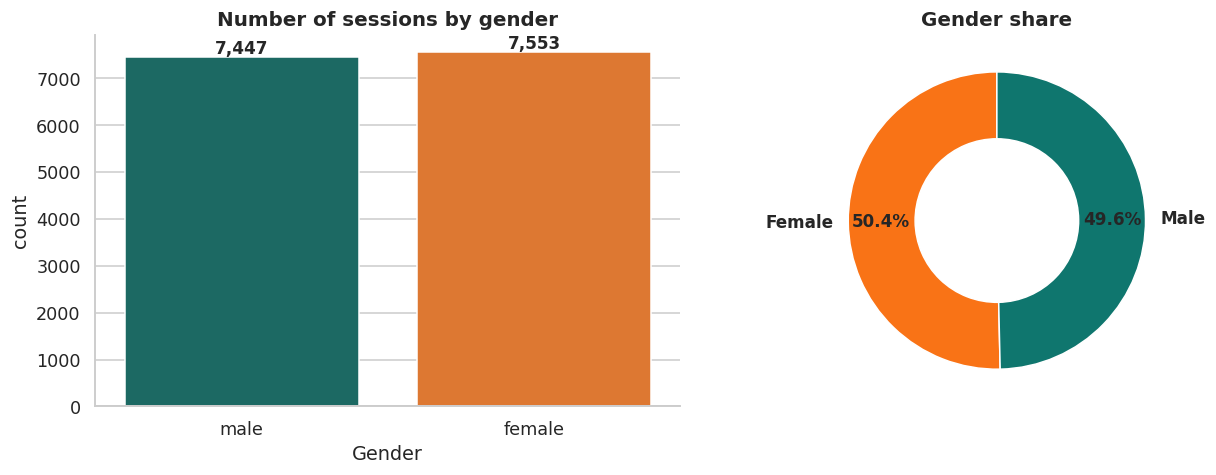

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts = calories_data['Gender'].value_counts()

sns.countplot(data=calories_data, x='Gender', hue='Gender', palette=GENDER_COLORS, ax=axes[0], legend=False)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[0].set_title('Number of sessions by gender')

axes[1].pie(counts, labels=counts.index.str.title(), autopct='%1.1f%%', startangle=90,
            colors=[GENDER_COLORS[g] for g in counts.index],
            pctdistance=0.78, wedgeprops=dict(width=0.45, edgecolor='white'), textprops=dict(fontsize=11, fontweight='bold'))
axes[1].set_title('Gender share')
plt.tight_layout(); plt.show()

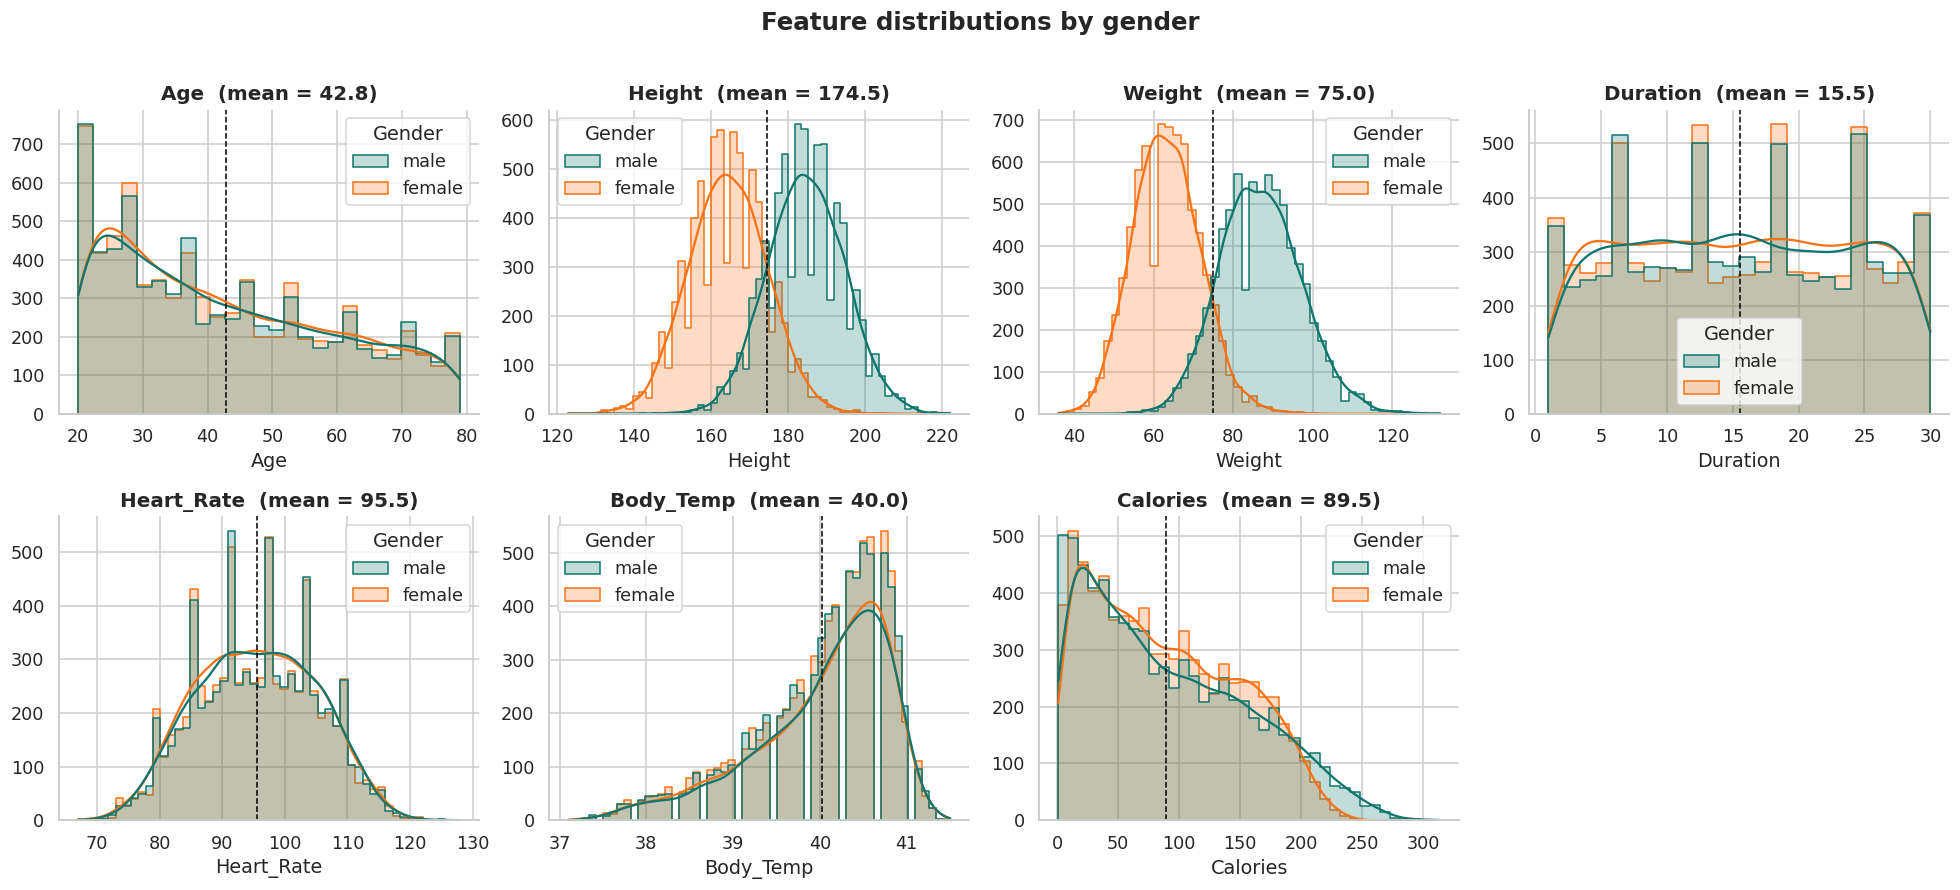

In [6]:
num_cols = ['Age', 'Height', 'Weight', 'Duration', 'Heart_Rate', 'Body_Temp', 'Calories']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=calories_data, x=col, hue='Gender', palette=GENDER_COLORS,
                 kde=True, element='step', alpha=0.25, ax=ax)
    ax.axvline(calories_data[col].mean(), color='black', ls='--', lw=1)
    ax.set_title(f'{col}  (mean = {calories_data[col].mean():.1f})')
    ax.set_ylabel('')
axes.flat[-1].axis('off')
fig.suptitle('Feature distributions by gender', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

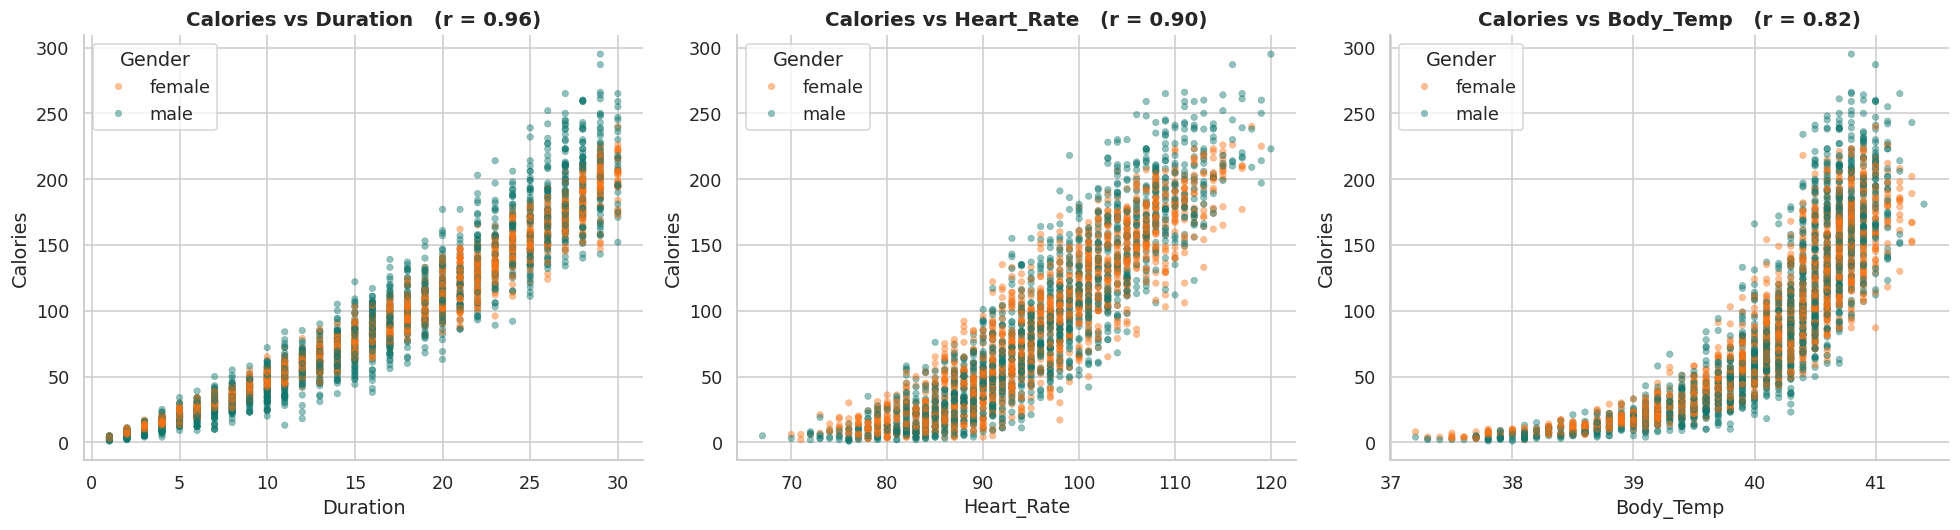

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sample = calories_data.sample(3000, random_state=42)   # sampled to keep the plot readable
for ax, col in zip(axes, ['Duration', 'Heart_Rate', 'Body_Temp']):
    sns.scatterplot(data=sample, x=col, y='Calories', hue='Gender', palette=GENDER_COLORS,
                    alpha=0.45, s=18, edgecolor=None, ax=ax)
    r = calories_data[col].corr(calories_data['Calories'])
    ax.set_title(f'Calories vs {col}   (r = {r:.2f})')
plt.tight_layout(); plt.show()

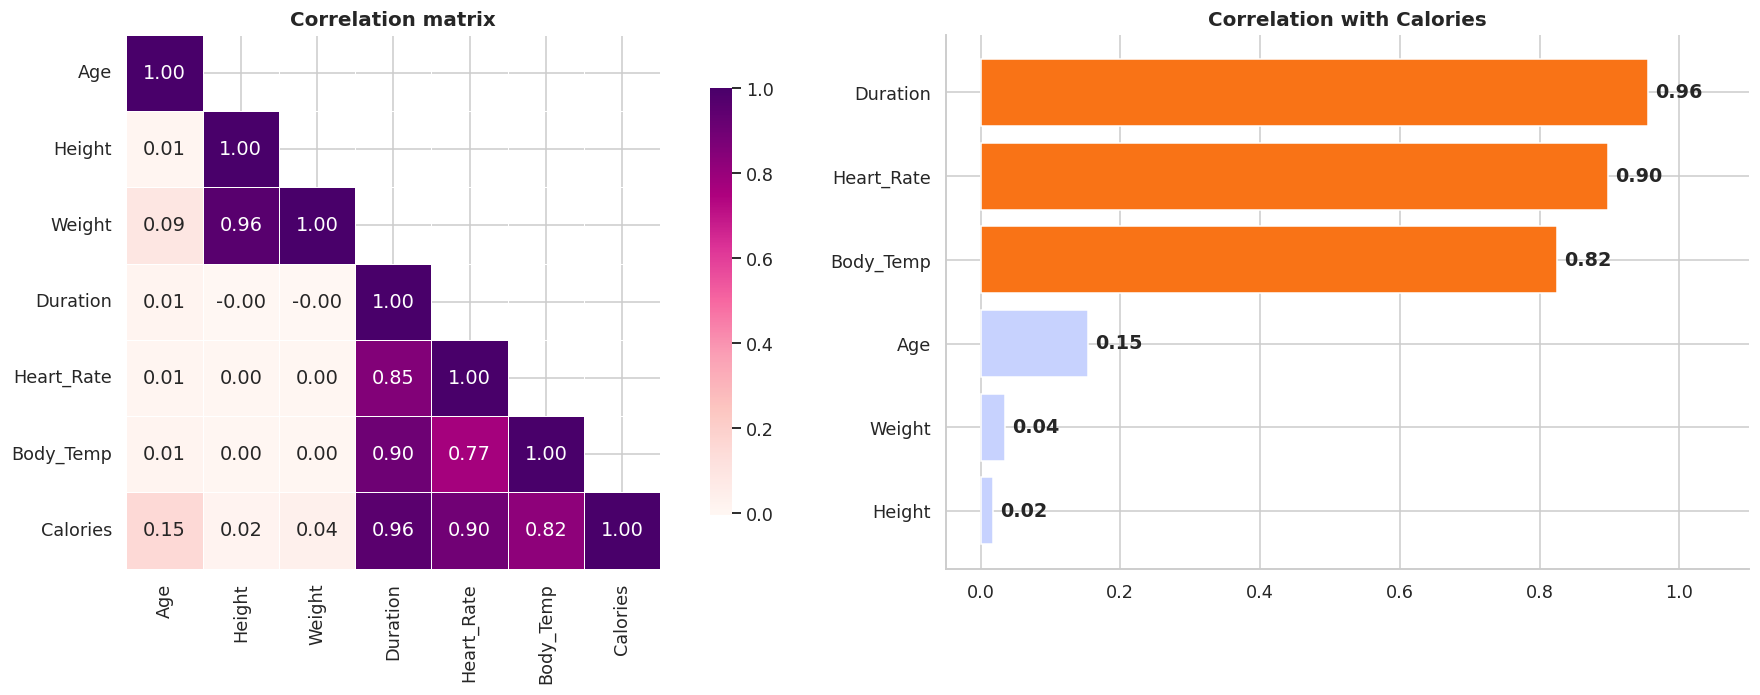

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={'width_ratios': [1.25, 1]})

corr = calories_data.drop(columns='User_ID').corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdPu', square=True,
            linewidths=0.6, cbar_kws={'shrink': .8}, ax=axes[0])
axes[0].set_title('Correlation matrix')

target_corr = corr['Calories'].drop('Calories').sort_values()
colors = [HOT if v > 0.5 else '#c7d2fe' for v in target_corr]
axes[1].barh(target_corr.index, target_corr.values, color=colors)
for i, v in enumerate(target_corr.values):
    axes[1].text(max(v, 0) + 0.01, i, f'{v:.2f}', va='center', fontweight='bold')
axes[1].set_xlim(min(0, target_corr.min()) - 0.05, 1.1)
axes[1].set_title('Correlation with Calories')
plt.tight_layout(); plt.show()

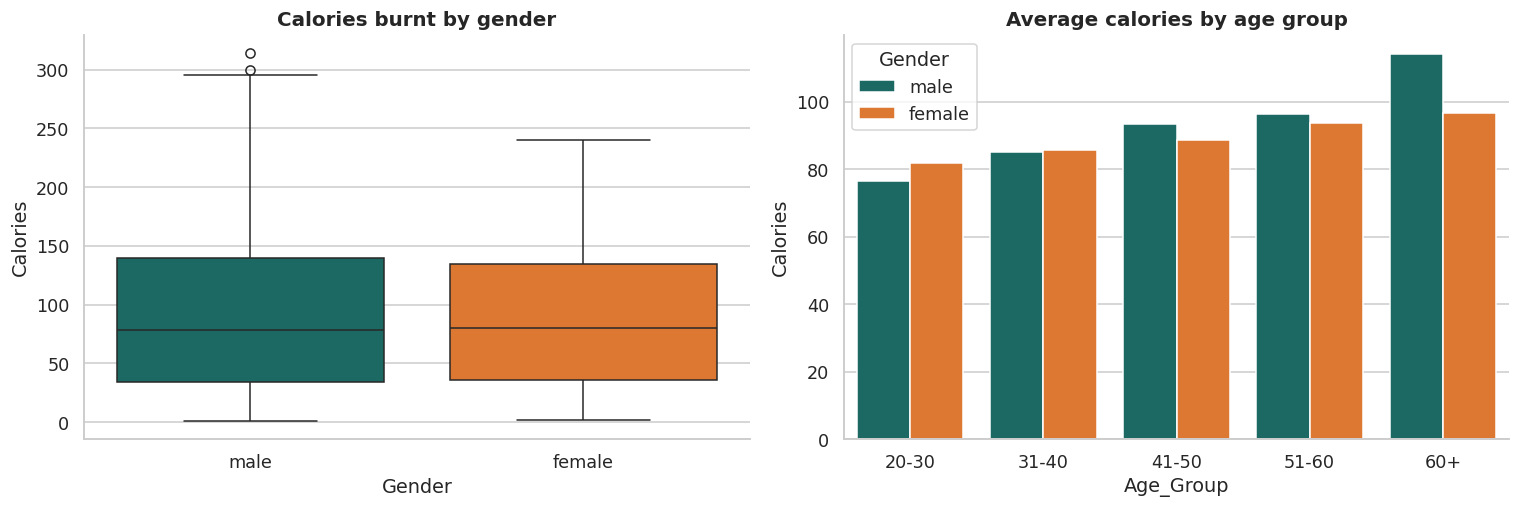

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=calories_data, x='Gender', y='Calories', hue='Gender', palette=GENDER_COLORS, ax=axes[0], legend=False)
axes[0].set_title('Calories burnt by gender')

age_group = pd.cut(calories_data['Age'], bins=[19, 30, 40, 50, 60, 80],
                   labels=['20-30', '31-40', '41-50', '51-60', '60+'])
sns.barplot(data=calories_data.assign(Age_Group=age_group), x='Age_Group', y='Calories',
            hue='Gender', palette=GENDER_COLORS, errorbar=None, ax=axes[1])
axes[1].set_title('Average calories by age group')
plt.tight_layout(); plt.show()

In [10]:
calories_data['Gender'] = calories_data['Gender'].map({'male': 0, 'female': 1})

X = calories_data.drop(columns=['User_ID', 'Calories'])
Y = calories_data['Calories']
FEATURES = list(X.columns)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print(f'Features : {FEATURES}')
print(f'Train    : {X_train.shape[0]:,} rows')
print(f'Test     : {X_test.shape[0]:,} rows')

Features : ['Gender', 'Age', 'Height', 'Weight', 'Duration', 'Heart_Rate', 'Body_Temp']
Train    : 12,000 rows
Test     : 3,000 rows


In [11]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree'    : DecisionTreeRegressor(random_state=2),
    'Random Forest'    : RandomForestRegressor(n_estimators=200, random_state=2, n_jobs=-1),
    'XGBoost'          : XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=5,
                                      subsample=0.9, colsample_bytree=0.9, random_state=2),
}

rows, predictions = [], {}
for name, mdl in models.items():
    t0 = time.time()
    mdl.fit(X_train, Y_train)
    elapsed = time.time() - t0
    pred = mdl.predict(X_test)
    predictions[name] = pred
    rows.append({
        'Model'  : name,
        'MAE'    : metrics.mean_absolute_error(Y_test, pred),
        'RMSE'   : np.sqrt(metrics.mean_squared_error(Y_test, pred)),
        'R²'     : metrics.r2_score(Y_test, pred),
        'Train time (s)': elapsed,
    })
    print(f'✔ {name:<18} MAE = {rows[-1]["MAE"]:.3f} kcal')

results = pd.DataFrame(rows).set_index('Model').sort_values('MAE')
best_name  = results.index[0]
best_model = models[best_name]
print(f'\n🏆 Best model: {best_name}')

(results.style
    .highlight_min(subset=['MAE', 'RMSE'], color='#bbf7d0')
    .highlight_max(subset=['R²'], color='#bbf7d0')
    .format({'MAE': '{:.3f}', 'RMSE': '{:.3f}', 'R²': '{:.5f}', 'Train time (s)': '{:.2f}'}))

✔ Linear Regression  MAE = 8.385 kcal
✔ Decision Tree      MAE = 3.421 kcal
✔ Random Forest      MAE = 1.658 kcal
✔ XGBoost            MAE = 0.784 kcal

🏆 Best model: XGBoost


,MAE,RMSE,R²,Train time (s)
Model,,,,
XGBoost,0.784,1.134,0.99967,1.13
Random Forest,1.658,2.616,0.99826,12.27
Decision Tree,3.421,5.340,0.99274,0.26
Linear Regression,8.385,11.406,0.96688,0.06


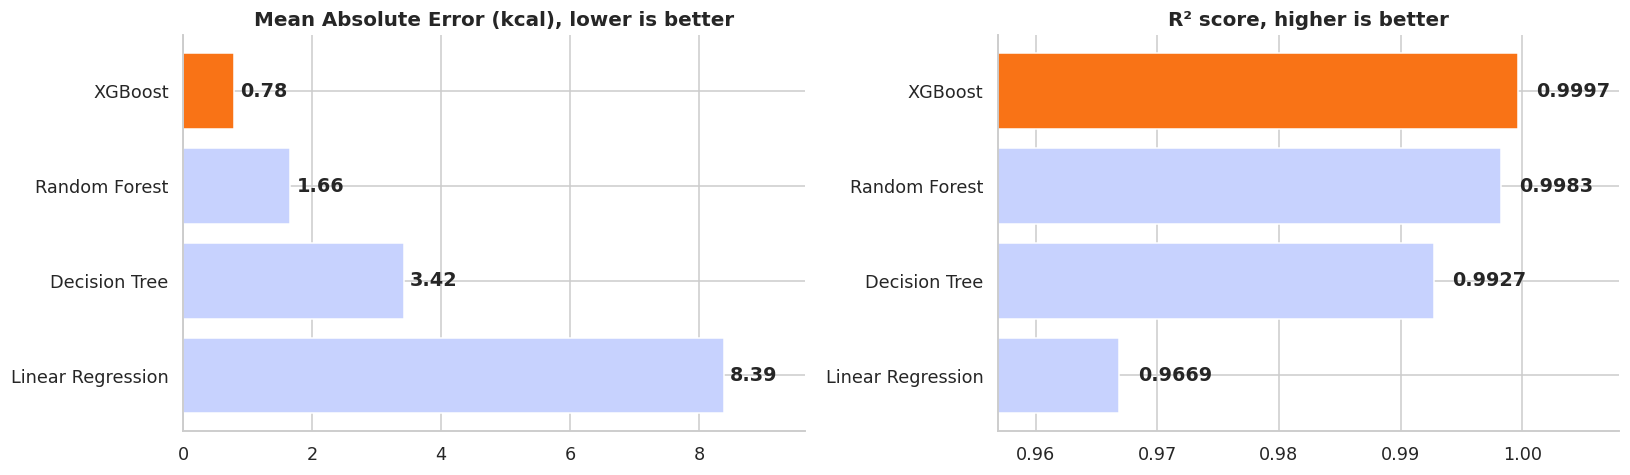

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
order = results.index[::-1]
bar_colors = [HOT if m == best_name else '#c7d2fe' for m in order]

axes[0].barh(order, results.loc[order, 'MAE'], color=bar_colors)
for i, v in enumerate(results.loc[order, 'MAE']):
    axes[0].text(v + 0.1, i, f'{v:.2f}', va='center', fontweight='bold')
axes[0].set_xlim(0, results['MAE'].max() * 1.15)
axes[0].set_title('Mean Absolute Error (kcal), lower is better')

axes[1].barh(order, results.loc[order, 'R²'], color=bar_colors)
for i, v in enumerate(results.loc[order, 'R²']):
    axes[1].text(v + 0.0015, i, f'{v:.4f}', va='center', fontweight='bold')
axes[1].set_xlim(results['R²'].min() - 0.01, 1.008)
axes[1].set_title('R² score, higher is better')
plt.tight_layout(); plt.show()

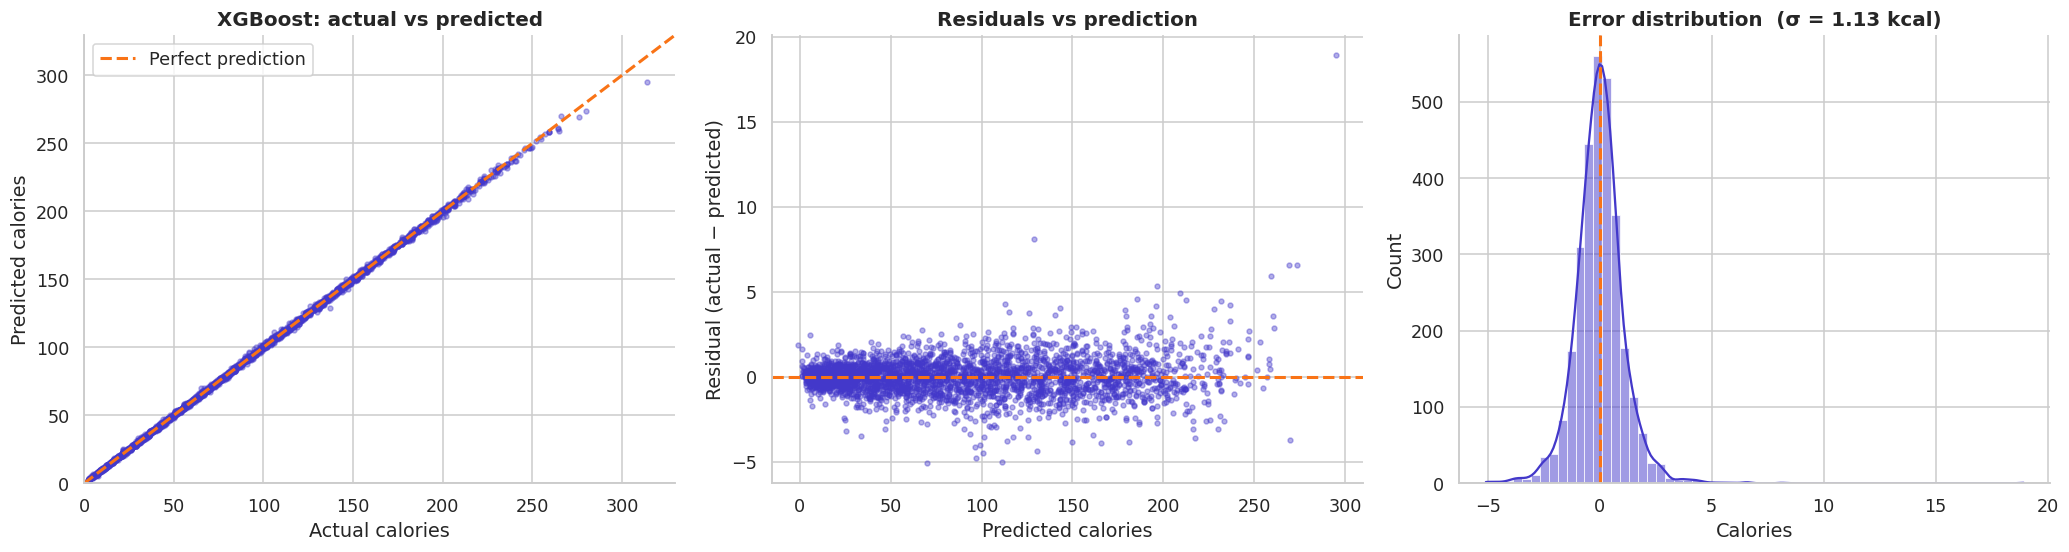

📌 99.7% of test predictions are within ±5 kcal of the true value


In [13]:
best_pred = predictions[best_name]
residuals = Y_test - best_pred

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))

axes[0].scatter(Y_test, best_pred, s=10, alpha=0.4, color=ACCENT)
lims = [0, Y_test.max() * 1.05]
axes[0].plot(lims, lims, color=HOT, lw=2, ls='--', label='Perfect prediction')
axes[0].set(xlim=lims, ylim=lims, xlabel='Actual calories', ylabel='Predicted calories')
axes[0].set_title(f'{best_name}: actual vs predicted'); axes[0].legend()

axes[1].scatter(best_pred, residuals, s=10, alpha=0.4, color=ACCENT)
axes[1].axhline(0, color=HOT, lw=2, ls='--')
axes[1].set(xlabel='Predicted calories', ylabel='Residual (actual − predicted)')
axes[1].set_title('Residuals vs prediction')

sns.histplot(residuals, bins=60, kde=True, color=ACCENT, ax=axes[2])
axes[2].axvline(0, color=HOT, lw=2, ls='--')
axes[2].set_title(f'Error distribution  (σ = {residuals.std():.2f} kcal)')
plt.tight_layout(); plt.show()

within = (np.abs(residuals) <= 5).mean() * 100
print(f'📌 {within:.1f}% of test predictions are within ±5 kcal of the true value')

In [14]:
# 5-fold cross-validation: checks that the score is not a lucky split
cv = KFold(n_splits=5, shuffle=True, random_state=2)
cv_mae = -cross_val_score(best_model, X, Y, cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1)
print(f'{best_name} 5-fold CV MAE: {cv_mae.mean():.3f} ± {cv_mae.std():.3f} kcal')
print('Per-fold:', np.round(cv_mae, 3))

XGBoost 5-fold CV MAE: 0.817 ± 0.021 kcal
Per-fold: [0.784 0.842 0.805 0.836 0.818]


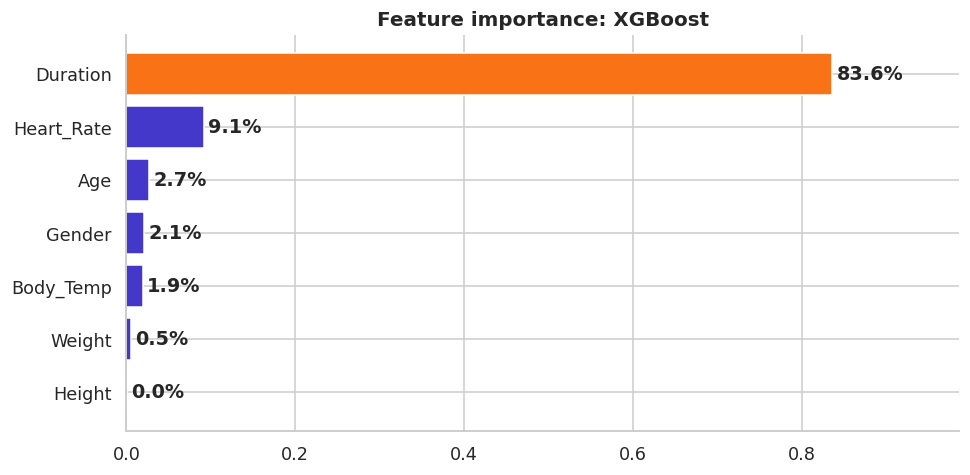

In [15]:
if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values()
    plt.figure(figsize=(9, 4.5))
    bars = plt.barh(imp.index, imp.values, color=[HOT if v == imp.max() else ACCENT for v in imp.values])
    for b, v in zip(bars, imp.values):
        plt.text(v + 0.005, b.get_y() + b.get_height()/2, f'{v:.1%}', va='center', fontweight='bold')
    plt.title(f'Feature importance: {best_name}')
    plt.xlim(0, imp.max() * 1.18)
    plt.tight_layout(); plt.show()

In [16]:
# Valid ranges taken from the training data
RANGES = {c: (float(X[c].min()), float(X[c].max())) for c in FEATURES if c != 'Gender'}
UNITS  = {'Age': 'yrs', 'Height': 'cm', 'Weight': 'kg', 'Duration': 'min', 'Heart_Rate': 'bpm', 'Body_Temp': '°C'}

def predict_calories(gender, age, height, weight, duration, heart_rate, body_temp, model=best_model):
    g = 0 if str(gender).strip().lower() in ('male', 'm', '0') else 1
    row = pd.DataFrame([[g, age, height, weight, duration, heart_rate, body_temp]], columns=FEATURES)
    return max(float(model.predict(row)[0]), 0.0)

def show_prediction(gender, age, height, weight, duration, heart_rate, body_temp):
    inputs = dict(Age=age, Height=height, Weight=weight, Duration=duration, Heart_Rate=heart_rate, Body_Temp=body_temp)
    kcal   = predict_calories(gender, age, height, weight, duration, heart_rate, body_temp)
    bmi    = weight / (height / 100) ** 2
    pct    = (Y < kcal).mean() * 100
    rate   = kcal / duration if duration else 0
    warn   = [f'{k} = {v:g} {UNITS[k]} (trained on {RANGES[k][0]:g}–{RANGES[k][1]:g})'
              for k, v in inputs.items() if not RANGES[k][0] <= v <= RANGES[k][1]]
    bmi_lbl = 'Underweight' if bmi < 18.5 else 'Normal' if bmi < 25 else 'Overweight' if bmi < 30 else 'Obese'
    intensity = 'Light 🟢' if rate < 4 else 'Moderate 🟡' if rate < 7 else 'Vigorous 🔴'

    chip = lambda label, val: (f'<div style="background:rgba(255,255,255,.14);padding:10px 14px;border-radius:10px;min-width:120px">'
                               f'<div style="font-size:.78em;opacity:.8">{label}</div><div style="font-size:1.15em;font-weight:700">{val}</div></div>')
    warn_html = ('<div style="margin-top:14px;background:#fef3c7;color:#92400e;padding:10px 14px;border-radius:10px;font-size:.9em">'
                 '⚠️ Outside training range, so treat this estimate with caution:<br>' + '<br>'.join(warn) + '</div>') if warn else ''
    display(HTML(f'''
    <div style="font-family:system-ui,sans-serif;background:linear-gradient(135deg,#1e1b4b,#4338ca 60%,#f97316);
                color:white;padding:24px 28px;border-radius:16px;max-width:760px">
      <div style="font-size:.95em;opacity:.85">{str(gender).title()} · {age:g} yrs · {height:g} cm · {weight:g} kg · {duration:g} min · {heart_rate:g} bpm · {body_temp:g} °C</div>
      <div style="font-size:3em;font-weight:800;margin:6px 0 2px">🔥 {kcal:.1f} kcal</div>
      <div style="opacity:.9">estimated calories burnt by <b>{best_name}</b> (typical error ±{results.loc[best_name, "MAE"]:.1f} kcal)</div>
      <div style="display:flex;gap:10px;flex-wrap:wrap;margin-top:16px">
        {chip('Burn rate', f'{rate:.1f} kcal/min')}
        {chip('Intensity', intensity)}
        {chip('BMI', f'{bmi:.1f} ({bmi_lbl})')}
        {chip('Higher than', f'{pct:.0f}% of sessions')}
      </div>
      <div style="margin-top:14px;font-size:.92em;opacity:.9">
        ≈ {kcal/105:.1f} bananas &nbsp;·&nbsp; ≈ {kcal/100:.1f} rotis &nbsp;·&nbsp; ≈ {kcal/78:.1f} boiled eggs <span style="opacity:.7">(approx.)</span>
      </div>
      {warn_html}
    </div>'''))

    # What-if curve: same person, different workout lengths
    durations = np.arange(1, 31)
    curve = [predict_calories(gender, age, height, weight, d, heart_rate, body_temp) for d in durations]
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(durations, curve, color=ACCENT, lw=2.5)
    ax.fill_between(durations, curve, alpha=0.12, color=ACCENT)
    ax.scatter([min(duration, 30)], [predict_calories(gender, age, height, weight, min(duration, 30), heart_rate, body_temp)],
               s=140, color=HOT, zorder=5, edgecolor='white', lw=2, label='Your workout')
    ax.set(xlabel='Workout duration (min)', ylabel='Predicted calories',
           title='What if you worked out longer? (same heart rate & body temp)')
    ax.legend(); plt.tight_layout(); plt.show()
    return kcal

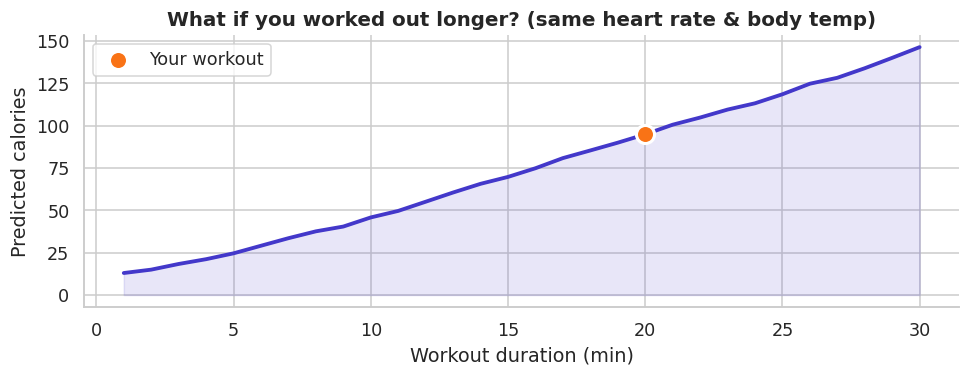

In [17]:
# ▶ Example: edit these values and re-run
show_prediction(gender='male', age=25, height=175, weight=70,
                duration=20, heart_rate=100, body_temp=40.2);

🔮 Calories Burnt Predictor
────────────────────────────────
Gender (male/female) [male]: male
Age (years) [25]: 30
Height (cm) [170]: 160
Weight (kg) [70]: 60
Workout duration (minutes) [20]: 30
Average heart rate during workout (bpm) [100]: 101
Body temperature during workout (°C) [40.0]: 30
   ↳ please enter a value between 35 and 43
Body temperature during workout (°C) [40.0]: 34
   ↳ please enter a value between 35 and 43
Body temperature during workout (°C) [40.0]: 34
   ↳ please enter a value between 35 and 43
Body temperature during workout (°C) [40.0]: 36



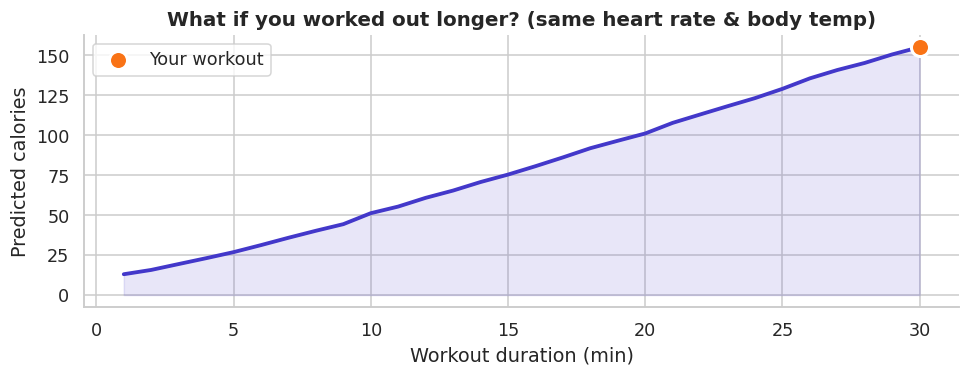

In [18]:
def ask(prompt, default, lo, hi, cast=float):
    while True:
        raw = input(f'{prompt} [{default}]: ').strip()
        if raw == '':
            return default
        try:
            val = cast(raw)
        except ValueError:
            print('   ↳ please enter a number'); continue
        if lo <= val <= hi:
            return val
        print(f'   ↳ please enter a value between {lo} and {hi}')

def ask_gender():
    while True:
        g = input('Gender (male/female) [male]: ').strip().lower() or 'male'
        if g in ('male', 'm', 'female', 'f'):
            return 'male' if g.startswith('m') else 'female'
        print('   ↳ type male or female')

print('🔮 Calories Burnt Predictor\n' + '─' * 32)
user = dict(
    gender     = ask_gender(),
    age        = ask('Age (years)', 25, 10, 100, int),
    height     = ask('Height (cm)', 170, 100, 230),
    weight     = ask('Weight (kg)', 70, 30, 200),
    duration   = ask('Workout duration (minutes)', 20, 1, 180),
    heart_rate = ask('Average heart rate during workout (bpm)', 100, 50, 200),
    body_temp  = ask('Body temperature during workout (°C)', 40.0, 35, 43),
)
print()
show_prediction(**user);

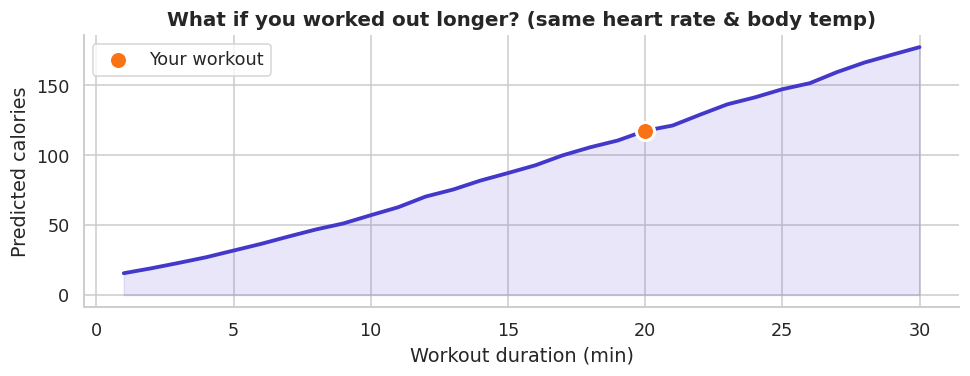

In [19]:
import ipywidgets as w

style  = {'description_width': '140px'}
layout = w.Layout(width='460px')
def slider(desc, col, val, step):
    lo, hi = RANGES[col]
    if isinstance(step, float):
        return w.FloatSlider(value=val, min=lo, max=hi, step=step, description=desc,
                             style=style, layout=layout, continuous_update=False, readout_format='.1f')
    return w.IntSlider(value=val, min=int(lo), max=int(hi), step=step, description=desc,
                       style=style, layout=layout, continuous_update=False)

gender_w = w.ToggleButtons(options=[('♂ Male', 'male'), ('♀ Female', 'female')], description='Gender', style=style)
age_w    = slider('Age (yrs)',        'Age',        25,   1)
height_w = slider('Height (cm)',      'Height',     175,  1)
weight_w = slider('Weight (kg)',      'Weight',     70,   1)
dur_w    = slider('Duration (min)',   'Duration',   20,   1)
hr_w     = slider('Heart rate (bpm)', 'Heart_Rate', 100,  1)
temp_w   = slider('Body temp (°C)',   'Body_Temp',  40.2, 0.1)
btn      = w.Button(description='🔥 Predict calories', button_style='warning', layout=w.Layout(width='220px', height='40px'))
out      = w.Output()

def on_click(_):
    with out:
        out.clear_output(wait=True)
        show_prediction(gender_w.value, age_w.value, height_w.value, weight_w.value,
                        dur_w.value, hr_w.value, round(temp_w.value, 1))
btn.on_click(on_click)

display(w.VBox([w.HTML('<h3 style="margin:0 0 6px">🔮 Calories Burnt Predictor</h3>'),
                gender_w, age_w, height_w, weight_w, dur_w, hr_w, temp_w, btn, out]))